# Practice Session 02: Data cleaning

Author: <font color="#2680EB">Anna Quílez Rodríguez</font>

E-mail: <font color="#2680EB">anna.quilez01@estudiant.upf.edu</font>

AI used: <font color="#2680EB">ChatGPT. I used artificial intelligence to help me understand the functions I wasn’t familiar with and to write some of the code.</font>

Date: <font color="#2680EB">6/10/2026</font>

In [35]:
# LEAVE AS-IS

# Required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [36]:
# LEAVE AS-IS
input_dataset = pd.read_csv("data/airbnb/listings_clean.csv.gz",compression="gzip")

# 1. Clean (data about) bathrooms <font color="#2680EB">[20%]</font>

In [37]:
# LEAVE AS-IS

def bathroom_crosstab(df):
    crosstab = pd.crosstab(
        df["bathrooms"].fillna("(null)"),
        df["bathrooms_text"].fillna("(null)")
    )
    display(crosstab)
    
bathroom_crosstab(input_dataset)

bathrooms_text,0 baths,0 shared baths,1 bath,1 private bath,1 shared bath,1.5 baths,1.5 shared baths,10 baths,11 baths,12 baths,...,5 baths,5 shared baths,5.5 baths,6 baths,7 baths,8 baths,9 baths,Half-bath,Private half-bath,Shared half-bath
bathrooms,,,,,,,,,,,,,,,,,,,,,
0.0,439,166,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
0.5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,5,25
1.0,1,0,5122,732,774,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.5,0,0,0,0,0,397,70,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2.0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2.5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3.5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [38]:
# LEAVE AS-IS
def check_bathrooms_text(df):
    
    # Extract number and text
    # The instructor used AI for the regexp (Claude Sonnet 5)
    extracted = df["bathrooms_text"].str.extract(r"^(\d+(?:\.\d+)?)\s(.*)$")
    extracted_number = extracted[0].astype(float)
    extracted_text = extracted[1]

    # Determine if singular or plural
    is_singular = extracted_text.isin(["bath", "private bath", "shared bath"])
    is_plural = extracted_text.isin(["baths", "private baths", "shared baths"])
    
    # Determine if private, otherwise shared
    is_shared = extracted_text.isin(["shared bath", "shared baths"])
        
    # 
    is_correct = \
        ((extracted_number == 0) & is_plural & ~is_shared) | \
        ((extracted_number == 0.5) & is_plural) | \
        ((extracted_number == 1) & is_singular) | \
        ((extracted_number > 1) & is_plural) 

    invalid_rows = df[~is_correct]
    if len(invalid_rows) > 0:
        print(f"Rows that do not pass the check: {len(invalid_rows)}")
        display(invalid_rows["bathrooms_text"].value_counts().reset_index())
        return False
    else:
        return True

check_bathrooms_text(input_dataset)
    

Rows that do not pass the check: 208


,bathrooms_text,count
0,0 shared baths,166
1,Shared half-bath,25
2,Half-bath,12
3,Private half-bath,5


False

<font size="+1" color="#2680EB">**Implement code to fix bathrooms_text**. Make sure all rows follow the constraint, fix the ones that do not. Do not drop any data. Use the function above that test that your data is now valid in this regard.</font>

In [39]:

def prepare_bathrooms_text(df):
    
    # YOUR CODE HERE
    df = df.copy()
    df["bathrooms_text"]=df["bathrooms_text"].replace({"0 shared baths": "0 baths",
                                                       "Shared half-bath": "0.5 shared baths",
                                                       "Half-bath": "0.5 baths",
                                                       "Private half-bath": "0.5 private baths"})
    return df

df2 = prepare_bathrooms_text(input_dataset)
check_bathrooms_text(df2)

True

<font size="+1" color="#2680EB">**Implement the code to prepare data about bathrooms**. Print the number of rows that were dropped</font>

In [40]:
def prepare_data_bathrooms(df):

    original_len = len(df)
    number_in_bathrooms_text = df["bathrooms_text"].str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
    
    # YOUR CODE HERE
    
    compatible = df["bathrooms"] == number_in_bathrooms_text
    
    df = df[compatible].copy()
    
    # Determine bathroom type
    df["bathrooms_type"] = "private"
    df.loc[df["bathrooms_text"].str.contains("shared"), "bathrooms_type"] = "shared"
    
    
    
    modified_len = len(df)
    print(f"Original: {original_len}, new: {modified_len}, dropped: {original_len - modified_len}")
    return df
    
df3 = prepare_data_bathrooms(df2)
display(df3[["bathrooms", "bathrooms_text", "bathrooms_type"]].drop_duplicates().sort_values("bathrooms"))

Original: 11482, new: 11479, dropped: 3


,bathrooms,bathrooms_text,bathrooms_type
36,0.0,0 baths,private
850,0.5,0.5 baths,private
1388,0.5,0.5 shared baths,shared
9731,0.5,0.5 private baths,private
109,1.0,1 private bath,private
3,1.0,1 bath,private
14,1.0,1 shared bath,shared
5,1.5,1.5 baths,private
113,1.5,1.5 shared baths,shared
1083,2.0,2 shared baths,shared


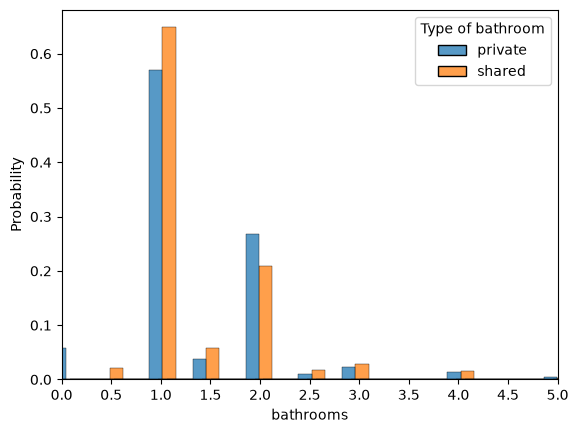

In [41]:
# LEAVE AS-IS

ax = sns.histplot(data=df3, x="bathrooms", 
                  stat="probability", common_norm=False,
                  hue="bathrooms_type", multiple="dodge", shrink=3)
ax.legend_.set_title("Type of bathroom")
plt.xticks(np.arange(0, 5.5, 0.5))
_ = plt.xlim(0, 5)

<font size="+1" color="#2680EB">**Describe what you see in the histogram above**.</font>

**Answer:** According to the histogram above:

* According to the histogram, the distribution of private and shared bathrooms is different depending on the number of bathrooms. For 0 and 0.5 bathrooms, all of them are private. For 1 bathroom, there are more shared bathrooms than private ones. The same happens for 1.5, 2.5, 3 and 4 bathrooms. However, for 2 bathrooms, there are more private bathrooms than shared ones. In general, there are fewer properties with a high number of bathrooms.
We can also see that, for both private and shared bathrooms, one bathroom is the most common case, followed by two bathrooms. Moreover, it makes sense that one bathroom is often shared because, in a property with several guests or residents, there may be a bathroom that is used by more than one person. However, the histogram does not show a clear general relationship between the number of bathrooms and whether they are private or shared.

# 2. Fix inconsistencies in bedrooms and beds <font color="#2680EB">[20%]</font>

In [42]:
# LEAVE AS-IS

def bedrooms_crosstab(df):
    crosstab = pd.crosstab(
        df["bedrooms"].fillna("(null)"),
        df["beds"].fillna("(null)")
    )
    display(crosstab)
    
bedrooms_crosstab(df3)

beds,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,24.0,25.0,26.0,30.0,31.0,32.0,33.0,35.0,37.0,127.0
bedrooms,,,,,,,,,,,,,,,,,,,,,
0.0,78,655,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.0,0,2595,1046,202,58,7,12,3,10,0,...,0,0,1,0,0,0,0,0,0,0
2.0,0,52,1527,1348,500,109,7,4,2,1,...,0,0,0,0,0,0,0,0,0,1
3.0,0,12,14,755,723,412,210,57,5,3,...,0,0,0,0,0,0,0,0,0,0
4.0,0,6,2,2,231,134,138,94,35,10,...,0,0,0,0,0,0,0,0,0,0
5.0,0,1,0,0,1,29,29,32,22,13,...,0,0,0,0,0,0,0,0,0,0
6.0,0,1,0,0,0,0,13,10,10,21,...,1,0,0,0,0,0,0,0,0,0
7.0,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
8.0,0,0,0,0,0,0,0,0,5,1,...,0,0,0,0,0,0,0,0,0,0


<font size="+1" color="#2680EB">**Describe the inconsistencies that can be observed in this matrix**. Answer the following questions.</font>

**Answer:**

In terms of bedrooms and beds, what does it mean in this case that most large values can be found near the diagonal?

* The diagonal represents cases where the number of bedrooms and beds is similar. We can see many cases such as 1 bedroom and 1 bed, 2 bedrooms and 2 beds, 2 bedrooms and 3 beds, or 3 bedrooms and 4 beds. We can also see many cases following the rule used previously to fill missing values, in practice 1, such as N beds and N-1 bedrooms.
Therefore, most values being near the diagonal means that the number of bedrooms and beds is usually similar, without big differences between them.

Do you see any gross inconsistency between the number of bedrooms and beds in some cases? Can you give an example of such inconsistency?

* Yes. There are some cases where the number of bedrooms is much larger than the number of beds.For example, there is a property with 29 bedrooms and only 1 bed, and another one with 19 bedrooms and 1 bed. These cases seem inconsistent because it is difficult to have so many bedrooms with only one bed. We also can see 2 bedrooms and 127 beds.

Assume that the number of beds is always correct, but that the number of bedrooms could have been miscounted. What validity criteria would you apply over the number of bedrooms, and what would you do in cases of violation of each criteria? For each validity criteria, indicate whether you will *fix* the data and how, or whether you will *drop* the row.

* A property with 0 beds should have 0 bedrooms: otherwise fix by setting bedrooms to 0. 
* If bedrooms > beds, I would drop the row.
* If there are many more beds than bedrooms could also be inconsistent, but I would not automatically drop them without a clear threshold, since the number of beds is assumed to be correct.
* If there is 1 bed and 0 bedrooms, we will keep the row because there are many cases with this combination (655 cases), so it does not necessarily indicate an error.


We will drop invalid rows in the data, but this may entail dropping some special cases that are actually correct.  Which correct cases do you think your rules may erroneously discard?

* Some valid cases could be incorrectly discarded. For example, a property could have more bedrooms than beds because some rooms may not have beds and could be used for other purposes.


<font size="+1" color="#2680EB">**Implement a check for your validy criteria**. Print the combinations of beds and bedrooms that fail the criteria.</font>

In [43]:
def check_bedrooms_beds(df):
    
    # YOUR CODE HERE
    valid1 = (df["beds"] != 0) | (df["bedrooms"] == 0)
    valid2 = df["bedrooms"] <= df["beds"]
    
    invalid_rows = df[~(valid1 & valid2)]
    
    
    if len(invalid_rows) > 0:
        print(f"Invalid rows: {len(invalid_rows)}")
        display(invalid_rows.groupby(["bedrooms", "beds"]).size().reset_index(name="count"))
        return False
    else:
        return True

check_bedrooms_beds(df3)

Invalid rows: 100


,bedrooms,beds,count
0,2.0,1.0,52
1,3.0,1.0,12
2,3.0,2.0,14
3,4.0,1.0,6
4,4.0,2.0,2
5,4.0,3.0,2
6,5.0,1.0,1
7,5.0,4.0,1
8,6.0,1.0,1
9,9.0,1.0,2


False

<font size="+1" color="#2680EB">**Implement data cleaning to ensure the validy criteria**. You can fix data or drop rows. If you drop rows, indicate how many did you drop.</font>

In [44]:
def fix_bedrooms_bed(df):
    df = df.copy()
    
    # YOUR CODE HERE
    # Fix cases with 0 beds
    df.loc[df["beds"] == 0, "bedrooms"] = 0
    
    # Drop cases where bedrooms is greater than beds
    invalid_rows = df["bedrooms"] > df["beds"]
    print(f"Dropped rows: {invalid_rows.sum()}")
    df = df[~invalid_rows]
    
    return df

df4 = fix_bedrooms_bed(df3)
check_bedrooms_beds(df4)

Dropped rows: 100


True

<Axes: xlabel='beds', ylabel='bedrooms'>

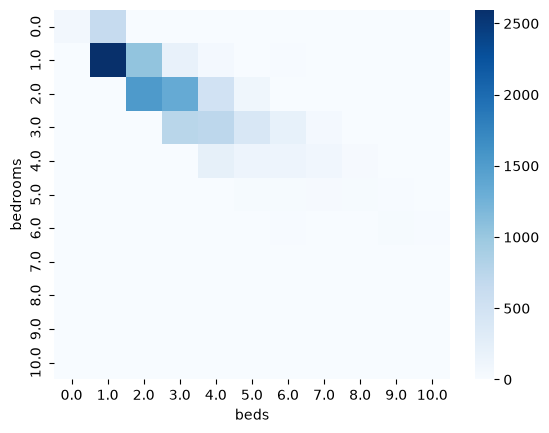

In [45]:
# LEAVE AS-IS

# The instructor used AI to understand crosstab filtering and Seaborn parameters (Claude Sonnet 5)
crosstab = pd.crosstab(df4["bedrooms"], df4["beds"])
crosstab = crosstab.loc[crosstab.index <= 10, crosstab.columns <= 10]
sns.heatmap(crosstab, cmap="Blues")

# 3. Categorize properties by size <font color="#2680EB">[10%]</font>

## 3.1. Fix fractional bathrooms

<font size="+1" color="#2680EB">**Implement code to convert the number of bathrooms**. Compute the floor of the number of bathrooms.</font>

In [46]:
def remove_fractional_bathrooms(df):
    df = df.copy()
    # YOUR CODE HERE
    df["bathrooms"] = df["bathrooms"] // 1
    return df
   
df5 = remove_fractional_bathrooms(df4)

<Axes: xlabel='bathrooms', ylabel='beds'>

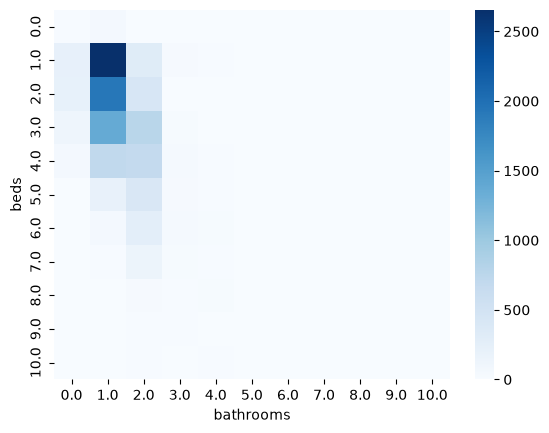

In [47]:
# LEAVE AS-IS

# The instructor used AI for crosstab filtering and Seaborn parameters (Claude Sonnet 5)
crosstab = pd.crosstab(df5["beds"], df5["bathrooms"])
crosstab = crosstab.loc[crosstab.index <= 10, crosstab.columns <= 10]
sns.heatmap(crosstab, cmap="Blues")

## 3.2. Create categories by size

<font size="+1" color="#2680EB">**Add a column "category" to the properties**. This can be "S", "M", "L", or "XL", and can depend on the number of beds, bedrooms, and/or bathrooms. Make sure that each category contains at least 500 properties.</font>

In [48]:
def add_category(df):
    df = df.copy()
    
    small = (df["beds"] == 1)
    df.loc[small, "category"] = "S"

    # YOUR CODE HERE
    medium = (df["beds"] == 2)
    df.loc[medium, "category"] = "M"

    large = (df["beds"] == 3)
    df.loc[large, "category"] = "L"

    extra_large = (df["beds"] >= 4)
    df.loc[extra_large, "category"] = "XL"
    # Convert size to ordinal variable
    size_ordinal = pd.CategoricalDtype(categories=["S", "M", "L", "XL"], ordered=True)
    df["category"] = df["category"].astype(size_ordinal)
    
    return df

df6 = add_category(df5)

display(df6.groupby(["category"], observed=True).size().reset_index(name="count"))


,category,count
0,S,3250
1,M,2573
2,L,2305
3,XL,3173


# 4. Analyze property size per neighborhood <font color="#2680EB">[10%]</font>

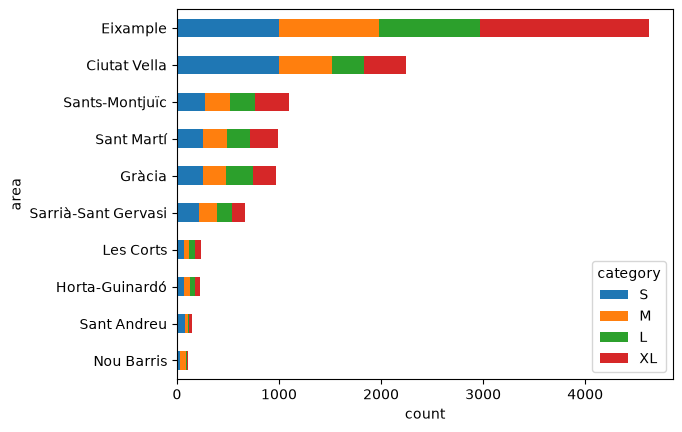

In [49]:
# LEAVE AS-IS

crosstab = pd.crosstab(df6["neighbourhood_group_cleansed"], df6["category"])
crosstab = crosstab.loc[crosstab.sum(axis=1).sort_values().index]
# The instructor used AI for stacked plot (Claude Sonnet 5)
crosstab.plot(kind="barh", stacked=True)
plt.xlabel("count")
_ = plt.ylabel("area")

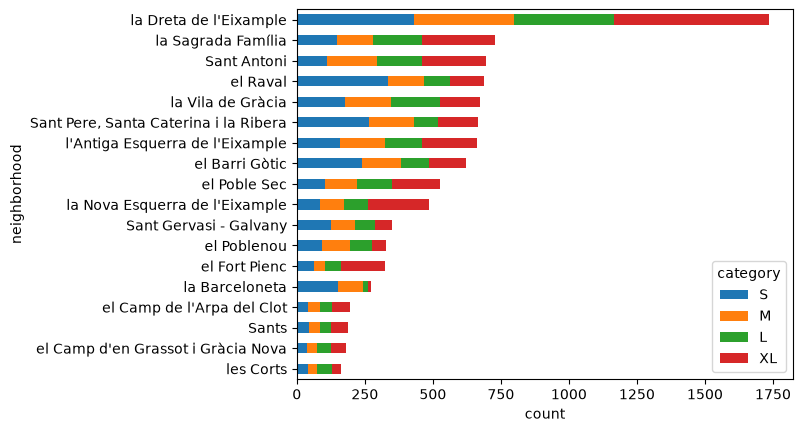

In [50]:
# LEAVE AS-IS

crosstab = pd.crosstab(df6["neighbourhood_cleansed"], df6["category"])
crosstab = crosstab[crosstab.sum(axis=1) >= 150]  # Only neighborhoods with at least this many properties
crosstab = crosstab.loc[crosstab.sum(axis=1).sort_values().index]
crosstab.plot(kind="barh", stacked=True)
plt.xlabel("count")
_ = plt.ylabel("neighborhood")


<font size="+1" color="#2680EB">**Describe what you see in the plots above**.</font>

**Answer:**

What do you observe regarding the areas and neighborhoods that concentrate the larger number of listings?

* Eixample has by far the most listings, followed by Ciutat Vella. Areas like Nou Barris, Sant Andreu and Horta-Guinardó have very few. At neighborhood level, la Dreta de l’Eixample has the highest number, then la Sagrada Família, Sant Antoni, el Raval and a few others in the center. Overall, the central areas of Barcelona concentrate most of the listings, while the more peripheral ones have much fewer.

What do you observe regarding the proportion of different property sizes per neighborhood?

* Looking at the previous distribution, most neighborhoods seem to have a fairly similar mix of S, M, L and XL properties. There are some differences (for example la Dreta de l’Eixample has more XL), but in general the proportionsof the different property sizes look quite similar across neighborhoods.

# 5. Group property types <font color="#2680EB">[10%]</font>

In [51]:
# LEAVE AS-IS

# The instructor used AI (Claude Sonnet 5)
display(df6.groupby(["property_type"], observed=True)
        .size().reset_index(name="count")
        .sort_values("count", ascending=False))


,property_type,count
11,Entire rental unit,8250
26,Private room in rental unit,1333
12,Entire serviced apartment,327
34,Room in hotel,257
4,Entire condo,249
24,Private room in hostel,195
9,Entire loft,144
32,Room in boutique hotel,103
23,Private room in home,100
7,Entire home,68


<font size="+1" color="#2680EB">**Add a column "property_type_group"**. Use the specification above.</font>

In [52]:
#AI

def add_property_type_group(df):
    df = df.copy()
    
    # YOUR CODE HERE
    df["property_type_group"] = ""

    room = df["property_type"].str.contains(
        "room", case=False, na=False
    )
    df.loc[room, "property_type_group"] = "room"

    unit = df["property_type"].str.contains(
        "Entire", case=False, na=False
    )
    df.loc[unit, "property_type_group"] = "unit"

    df = df[df["property_type_group"] != ""]
    return df

df7 = add_property_type_group(df6)
display(df7.groupby(["property_type", "property_type_group"], observed=True)
        .size().reset_index(name="count")
        .sort_values(["property_type_group", "count"], ascending=False))


,property_type,property_type_group,count
7,Entire rental unit,unit,8250
8,Entire serviced apartment,unit,327
0,Entire condo,unit,249
5,Entire loft,unit,144
3,Entire home,unit,68
9,Entire townhouse,unit,19
10,Entire vacation home,unit,18
1,Entire guest suite,unit,9
11,Entire villa,unit,6
2,Entire guesthouse,unit,4


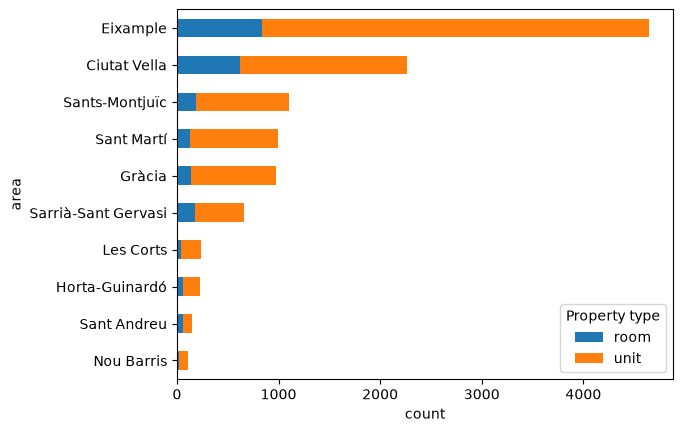

In [53]:
# LEAVE AS-IS

crosstab = pd.crosstab(df7["neighbourhood_group_cleansed"],
                       df7["property_type_group"])
crosstab = crosstab.loc[crosstab.sum(axis=1).sort_values().index]
ax = crosstab.plot(kind="barh", stacked=True)
ax.legend_.set_title("Property type")
plt.xlabel("count")
_ = plt.ylabel("area")

<font size="+1" color="#2680EB">**Describe what you see in the plot above**.</font>

**Answer:**

What do you observe regarding the property types per area?

* In all areas there are clearly more units than rooms. This makes sense because most people prefer to rent an entire apartment rather than just a room, and owners also earn more by renting the whole place. Eixample has by far the highest number of listings (mostly units), probably because it is a very central and attractive area for tourists. 
The rest of the areas have fewer listings and are also dominated by units.

# 6. Convert price to a numerical value <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Write code to convert the column price to a numerical value**.</font>

In [54]:
def convert_price_to_numeric(df):
    df = df.copy()
    
    # YOUR CODE HERE
    df["price"] = df["price"].str.replace(r"[$,]", "", regex=True)
    df["price"] = df["price"].astype(float)

    return df
    
df8 = convert_price_to_numeric(df7)

Text(0, 0.5, 'neighborhood')

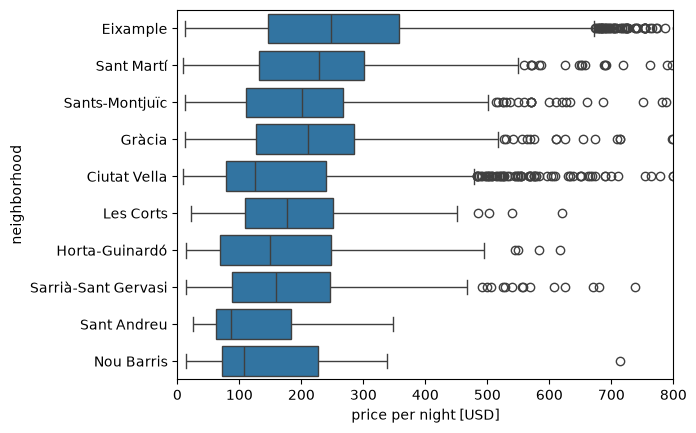

In [55]:
# LEAVE AS-IS

order = df8.groupby("neighbourhood_group_cleansed")["price"].mean().sort_values(ascending=False).index
sns.boxplot(data=df8, y="neighbourhood_group_cleansed", x="price", order=order)

plt.xlim(0, 800)
plt.xlabel("price per night [USD]")
plt.ylabel("neighborhood")

# 7. Analyze price and property size per area <font color="#2680EB">[20%]</font>

Text(0, 0.5, 'neighborhood')

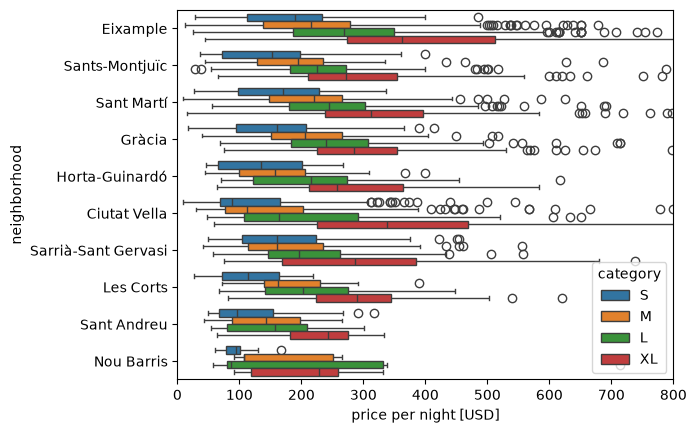

In [56]:
# LEAVE AS-IS

df9 = df8[df8["property_type_group"] == "unit"]

order = df9.groupby("neighbourhood_group_cleansed")["price"].mean().sort_values(ascending=False).index
# The instructor used AI for boxplot parameters (Claude Sonnet 5)
sns.boxplot(data=df9,
            y="neighbourhood_group_cleansed",
            x="price",
            hue="category",
            order=order)

plt.xlim(0, 800)
plt.xlabel("price per night [USD]")
plt.ylabel("neighborhood")

## 7.1. Relative price

<font size="+1" color="#2680EB">**Implement a computation of relative price**. First, compute the average price per size (S/M/L/XL), then, create the column *relative_price* as price/average price.</font>

In [57]:
#AI
def add_relative_price(df):
    df = df.copy()
     # YOUR CODE HERE
    average_price = df.groupby("category")["price"].mean().reset_index()
    average_price = average_price.rename(columns={"price": "average_price"})
    
    df = df.merge(average_price, on="category")
    
    df["price_relative"] = df["price"] / df["average_price"]
    
    return df
    
df10 = add_relative_price(df9)
df10.groupby("neighbourhood_group_cleansed")["price_relative"].mean().reset_index().sort_values("price_relative", ascending=False)

,neighbourhood_group_cleansed,price_relative
1,Eixample,1.158564
7,Sant Martí,0.976897
2,Gràcia,0.932801
8,Sants-Montjuïc,0.905662
9,Sarrià-Sant Gervasi,0.861597
0,Ciutat Vella,0.840351
3,Horta-Guinardó,0.818014
4,Les Corts,0.803643
5,Nou Barris,0.749357
6,Sant Andreu,0.717169


<font size="+1" color="#2680EB">**Write your observations on this relative price result**. 
</font>

**Answer:**

What do you observe regarding relative price?

* As we can see, Eixample is the only neighbourhood that goes above the average price of properties of the same size. This may be because it is an exclusive area, so the properties are more expensive. In the same way, the rest of the neighbourhoods are close to or below the average price according to their size. Given that we are comparing each property with properties of the same size, and all the neighbourhoods except Eixample are below the average price, we can see that there are differences between properties with the same size depending on the neighbourhood.


## 7.2. Size-adjusted average price

<font size="+1" color="#2680EB">**Implement a computation of size-adjusted price**. First, compute the average price per size (S/M/L/XL), then, compute a size-adjusted relative price. The output should be a dataframe with columns "neighbourhood_group_cleansed" and "size_adjusted_avg_price".</font>

In [58]:
#AI

def compute_size_adjusted_price(df):

    avg_price = df.groupby("category", observed=True)["price"].mean()

    # YOUR CODE HERE
    size_adjusted_price = (
        df.groupby("neighbourhood_group_cleansed", observed=True)
        .apply(
            lambda x: sum(x["category"].map(avg_price)) / len(x),
            include_groups=False
        )
        .reset_index(name="size_adjusted_avg_price")
    )

    return size_adjusted_price

size_adjusted_price = compute_size_adjusted_price(df10)
display(size_adjusted_price.reset_index().sort_values(["size_adjusted_avg_price"], ascending=False))

,index,neighbourhood_group_cleansed,size_adjusted_avg_price
1,1,Eixample,322.209982
8,8,Sants-Montjuïc,302.303920
7,7,Sant Martí,289.855731
3,3,Horta-Guinardó,287.896551
4,4,Les Corts,281.765750
2,2,Gràcia,277.346866
9,9,Sarrià-Sant Gervasi,273.906614
6,6,Sant Andreu,270.991089
0,0,Ciutat Vella,259.982174
5,5,Nou Barris,229.056233


<font size="+1" color="#2680EB">**Write your observations on this size-adjusted average price result**.
</font>

**Answer:**

What do you observe regarding size-adjusted average price?

* We can see that Eixample has the highest size-adjusted average price, while Nou Barris has the lowest. This means that, even if we replace the prices of the properties by the average price of their corresponding size in the city, Eixample would still have a higher average price than the other neighbourhoods. Therefore, the differences between neighbourhoods are not only related to the proportion of properties of each size.


Comparing the results you obtain using the relative price, is there any robust conclusion you can reach? 

* Comparing the two results, we can see that Eixample has the highest value in both analyses, while Nou Barris has the lowest value. However, the order of the other neighbourhoods changes between the two methods. Therefore, a robust conclusion is that the differences in price between neighbourhoods cannot be explained only by the size of the properties.


What are all the limitations of this analysis? Name at least three.

* Previously, when I decided how to classify small, medium, large and extra large, I used an easy distribution: S = 1 bed, M = 2 beds, L = 3 beds and XL = 4+ beds. In this way, in the extra large category we can have a property with 4 beds and another one with 10 beds, even though they can be very different in size. Another limitation is that we are doing an analysis based on size, whereas there are other characteristics that can be equally important, such as location, services, quality, etc. Given that we are using the average, there can be outliers that affect the mean. For example, if there is a property that is extremely expensive compared to the others, it can make the average price seem higher. Furthermore, we are analyzing a dataset where we do not have the whole population. Previously, we also had to drop some rows or make assumptions in order to deal with missing values, so this can also affect the results.



<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that I have not copied it from others, or from external sources without citing them, and that I have followed the generative AI instructions stated above.</font>